Predicted Class: Masked
Probability: 0.9995


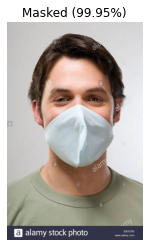

In [2]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

path = 'C:/Users/Administrator/AI/Mask_std/predict'
model_save_path = 'C:/Users/Administrator/AI/Mask_std/model_trained_data.h5'
class_labels = {0: 'Masked', 1: 'No Mask'}

# 모델 로드 (compile=False로 무거운 경고 코드 방지)
model = tf.keras.models.load_model(model_save_path, compile=False)

def test_image(img_name):
    # 1. 이미지 로드 및 전처리
    img_path = os.path.join(path, img_name)
    original_img = cv2.imread(img_path) # BGR 상태 유지
    
    if original_img is None:
        print(f"이미지를 찾을 수 없습니다: {img_path}")
        return
        
    # [중요] 학습 데이터와 똑같이 BGR 상태에서 리사이즈 및 정규화 진행!
    resized_img = cv2.resize(original_img, (128, 128)) / 255.0
    input_data = resized_img.reshape(1, 128, 128, 3) 

    # 2. 예측 및 결과 해석
    predictions = model.predict(input_data)
    raw_probability = predictions[0][0] 

    if raw_probability > 0.5:
        class_index = 1  # No Mask
        probability = raw_probability  
    else:
        class_index = 0  # Masked
        probability = 1.0 - raw_probability  

    # 3. 결과 출력
    print(f"Predicted Class: {class_labels.get(class_index)}")
    print(f"Probability: {probability:.4f}")

    # 화면에 보여줄 때만 사람이 보기 편하게 RGB로 변환
    display_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    plt.imshow(display_img)
    plt.title(f"{class_labels.get(class_index)} ({probability:.2%})")
    plt.axis('off')
    plt.show()

# 테스트 실행
test_image('0-12.jpg')

Predicted Class: No Mask
Probability: 0.9906


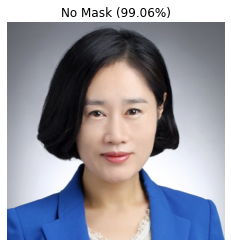

In [3]:
test_image('1-3.png')